# Understanding LFP Probe Layout and Data Loading with dclut Files
This supplementary tutorial covers the mechanics of LFP data loading with dclut files, probe geometry visualization, and spatial channel selection. These concepts are used behind the scenes in the automated loading functions, but understanding them helps you work with custom data formats and troubleshoot loading issues.

For the main spectral analysis workflow, see **AnalyzeLFPSpectral.ipynb**.

## Imports and Setup

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from mimo_pack.consts import DIM_TIME, DIM_CHAN, COORD_X, COORD_Y
from mimo_pack.fileio.lfp import load_lfp_full
from mimo_pack.analysis.probe import nearest_grid
from mimo_pack.plot.map import wave_map
from mimo_pack.plot.probe import probe_layout, channel_values, depth_lines


In [2]:
# path to LFP dclut file goes here
lfp_path = os.path.join('D:', 'SortingTemp', '24-05-31_DH23_A1-IC_g0', 
                         '24-05-31_DH23_A1-IC_g0_imec0', 
                         '24-05-31_DH23_A1-IC_g0_t0.imec0.lfp_dclut.json')

## Understanding Data Size and Channel Selection
Loading all recorded LFP data from a single session is often impractical due to the data size. This becomes especially problematic if you want to save wavelet spectrograms for all that data, since each data point is now stored as a complex number (which usually has twice the bytes) and for every frequency. However, since the LFP is often similar between adjacent electrodes, one can instead load a subset of the channels that are spaced far enough apart that they will tend to be less correlated. In most cases, a spacing of ~100 microns along both the x and y directions is satisfactory.

Let's start by setting up our dclut object for the LFP data and visualizing the locations of the electrodes.

<Axes: xlabel='X Position (µm)', ylabel='Y Position (µm)'>

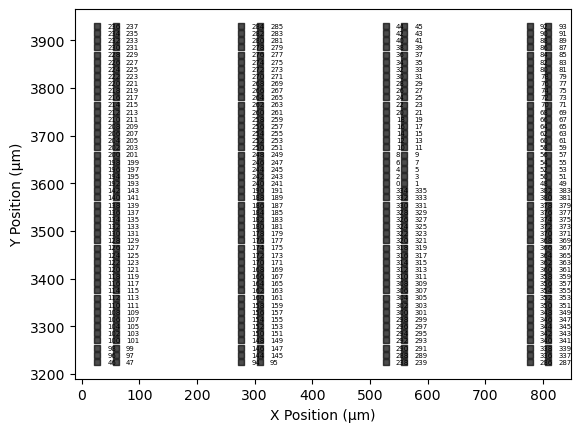

In [3]:
import dclut as dcl
lfp_dcl = dcl.dclut(lfp_path)

# Build a minimal DataArray from dclut probe coordinates for mimo_pack functions
ch_vals = lfp_dcl.scale_values('channel')
ch_x = lfp_dcl.scale_values('ch_x')
ch_y = lfp_dcl.scale_values('ch_y')
import xarray as xr
probe_da = xr.DataArray(
    np.zeros(len(ch_vals)),
    dims=[DIM_CHAN],
    coords={DIM_CHAN: ch_vals, COORD_X: (DIM_CHAN, ch_x), COORD_Y: (DIM_CHAN, ch_y)},
)

probe_layout(probe_da)


## Creating a Grid for Channel Selection
We will now create a grid of points that tile the area encompassed by the electrodes. We will start the grid with the 'lower left' point, and tile it across the entire area spanned by the electrodes. When setting the grid spacing, keep the arrangement of the electrodes in mind. I have created a function, `nearest_grid`, that returns the channels on a probe (specified by the dclut object), that are closest to points on a grid. For this example, 100 microns will work along the y-axis, but along the x-axis the spacing should be 250 microns.

Text(0.5, 1.0, 'Nearest grid points')

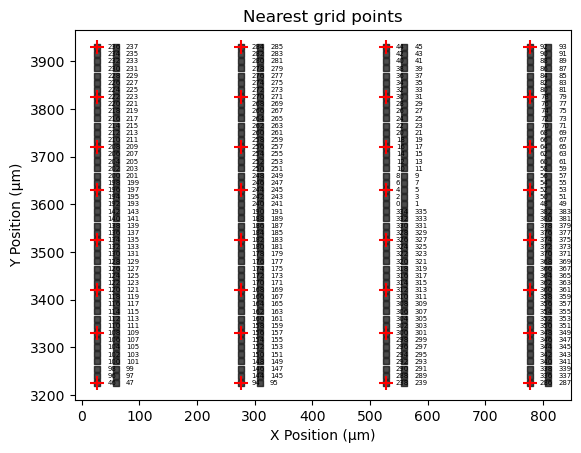

In [4]:
ch_grid, x_grid, y_grid = nearest_grid(probe_da, dx=250, dy=100)

# plot the grid points on the probe layout
ax = probe_layout(probe_da)
ax.scatter(x_grid, y_grid, s=100, c='r', marker='+')
ax.set_title('Nearest grid points')


## Understanding Xarray Structure
Now we just need to use those channels when selecting the electrodes whose signal we will load. We will read it in as an xarray object. These are multidimensional arrays that contain additional metadata specifing the values and names of dimensions. In brief, each dimension of the array has a name (e.g. 'time', 'channel'), and can have coordinates overlaid on them. For instance, our `lfp` xarray has a 'channel' dimension with coordinates for the x and y positions of each channel.

In [5]:
# Load the LFP data using load_lfp_full — handles channel selection,
# NaN time removal, and attribute population automatically
lfp = load_lfp_full(lfp_path, dx=250, dy=100)


`load_lfp_full` handles NaN time removal automatically (`remove_nan_time=True` by default), channel grid selection, and populates standard `attrs` (including `fs`). You can inspect the loaded object with `print(lfp)`.

You can see the dimensions and coordinates of the xarray object using the print function.


In [6]:
print(lfp)

<xarray.DataArray (time: 27011667, channel: 32)> Size: 2GB
array([[249, 258, 316, ..., 263, 259, 242],
       [233, 245, 310, ..., 260, 251, 241],
       [244, 254, 313, ..., 260, 251, 242],
       ...,
       [-28,  10,  53, ...,  30, -26,   0],
       [-22,  18,  60, ...,  41, -19,  12],
       [ -9,  30,  73, ...,  52, -10,  25]],
      shape=(27011667, 32), dtype=int16)
Coordinates:
  * time      (time) float64 216MB 0.0 0.0009998 0.002 ... 2.701e+04 2.701e+04
  * channel   (channel) int64 256B 46 108 120 134 196 208 ... 374 52 64 78 92
    ch_name   (channel) <U9 1kB 'AP46;46' 'AP108;108' ... 'AP78;78' 'AP92;92'
    ch_order  (channel) int64 256B 0 14 26 40 54 66 ... 314 328 342 354 368 382
    ch_x      (channel) float64 256B 27.0 27.0 27.0 27.0 ... 777.0 777.0 777.0
    ch_y      (channel) float64 256B 3.225e+03 3.33e+03 ... 3.825e+03 3.93e+03
    ch_shank  (channel) float64 256B 0.0 0.0 0.0 0.0 0.0 ... 3.0 3.0 3.0 3.0 3.0
    s0        (time) int64 216MB 0 1 2 3 ... 27011663 27

## Data Size Considerations
The top line lists the dimensions and the number of indices each of them has. Below that is a snippet of the data, and below that is a list of the coordinate names and their corresponding dimension in parentheses. Note that the object size is 2 GB. If we included all 384 channels, that would be $2GB \times \frac{384}{32}=24GB$. Not prohibitive, but excessive, especially considering how correlated the LFP is between sites on the order of 100 um.

With the data loaded, let's inspect it. We will plot a short segment of the LFP signal from each electrode, positioned where the electrode is. To do this, we will use the `wave_map` function in mimopack. It allows you to directly pass an xarray object with time and channel that has positional coordinates.

Text(0, 0.5, 'Y position (um)')

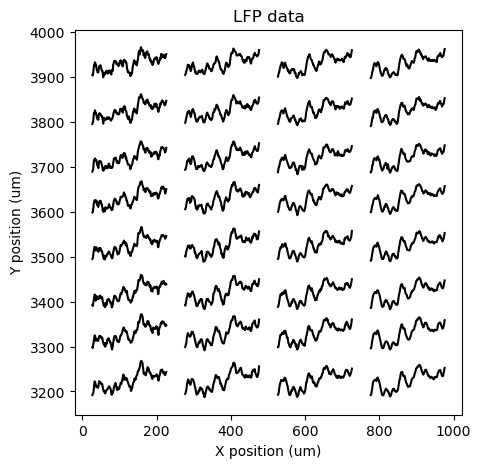

In [7]:
# select a time segment of the LFP data
t_start = 300.0
t_end = 300.2
sample = lfp.sel({DIM_TIME: slice(t_start, t_end)})

# remove the mean voltage from each channel, to avoid DC offset
sample = sample - sample.mean(dim=DIM_TIME)

# plot the LFP data
fig, ax = plt.subplots(figsize=(5, 5))
wave_map(sample, ax=ax, y_scale=0.5)
ax.set_title('LFP data')
ax.set_xlabel('X position (um)')
ax.set_ylabel('Y position (um)')


## Signal Visualization Examples

Now that you understand how to load and visualize LFP data, here are some examples demonstrating additional analysis techniques:

### Example 1: Compare Different Time Windows
Visualize LFP signals at different time points to observe changes in amplitude or patterns across time.

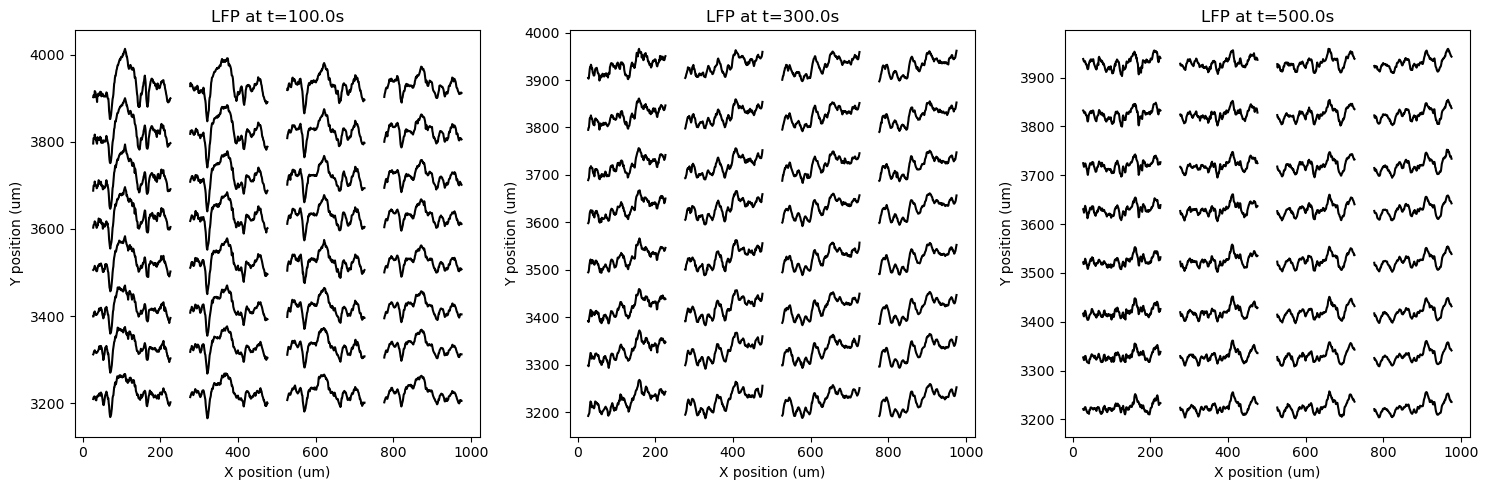

In [8]:
# Compare three different time windows
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
time_points = [100.0, 300.0, 500.0]

for i, t_start in enumerate(time_points):
    t_end = t_start + 0.2
    sample = lfp.sel({DIM_TIME: slice(t_start, t_end)})
    sample = sample - sample.mean(dim=DIM_TIME)

    wave_map(sample, ax=axes[i], y_scale=0.5)
    axes[i].set_title(f'LFP at t={t_start}s')
    axes[i].set_xlabel('X position (um)')
    axes[i].set_ylabel('Y position (um)')

plt.tight_layout()


### Example 2: Plot Individual Channel Traces
Select specific channels and plot their raw time-series data in separate subplots to see detailed waveforms.

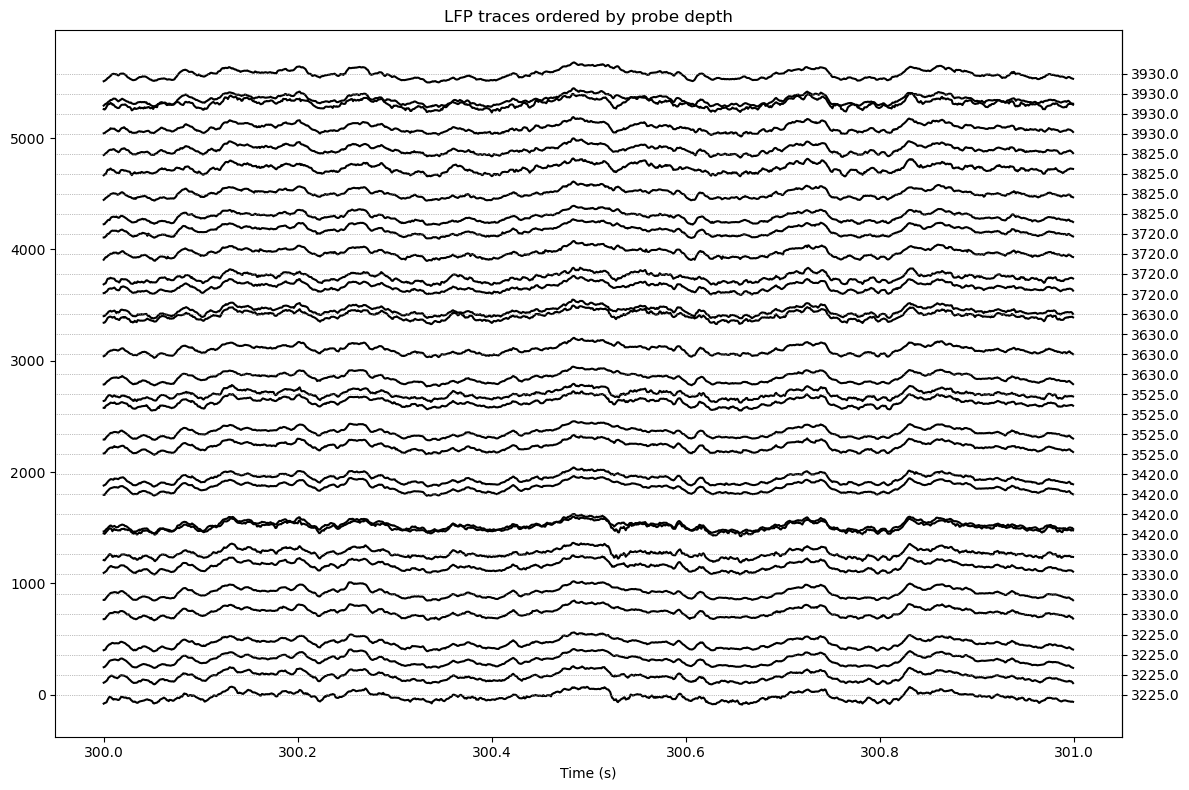

In [9]:
# Plot channels ordered by depth using depth_lines — channels are automatically
# sorted by their Y (depth) coordinate and labelled on the right axis
t_start, t_end = 300.0, 301.0
lfp_trace = lfp.sel({DIM_TIME: slice(t_start, t_end)})

fig, ax = plt.subplots(figsize=(12, 8))
depth_lines(lfp_trace, ax=ax)
ax.set_title('LFP traces ordered by probe depth')
plt.tight_layout()


### Example 3: Experiment with Grid Spacing
Load data with different grid spacings to see how it affects data size and spatial coverage. Sparser sampling reduces memory but may miss spatial details.

Sparse: 8 channels, Dense: 105 channels
Memory ratio: 13.1x more data with dense sampling


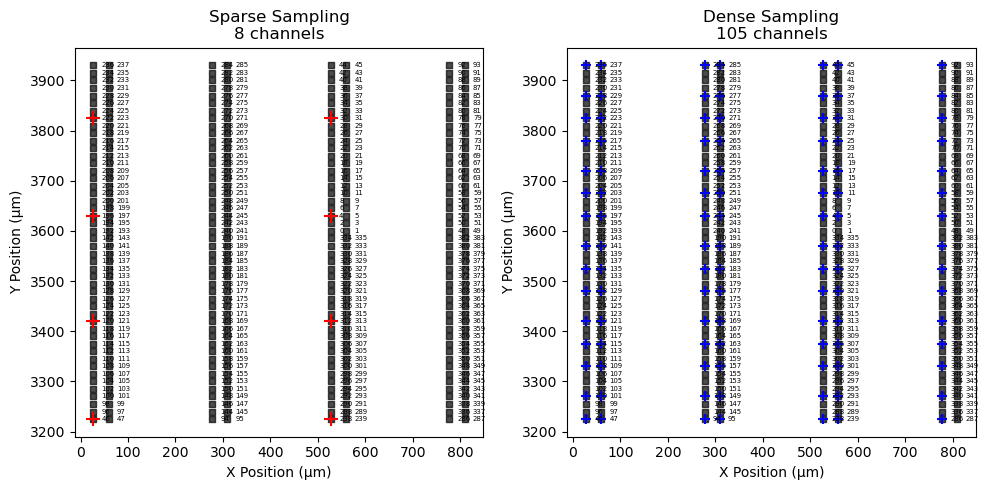

In [10]:
# Compare sparse vs dense sampling
import dclut as dcl
import xarray as xr
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

def make_probe_da(path):
    """Build a minimal probe DataArray from a dclut file."""
    d = dcl.dclut(path)
    ch_vals = d.scale_values('channel')
    ch_x = d.scale_values('ch_x')
    ch_y = d.scale_values('ch_y')
    return xr.DataArray(
        np.zeros(len(ch_vals)),
        dims=[DIM_CHAN],
        coords={DIM_CHAN: ch_vals, COORD_X: (DIM_CHAN, ch_x), COORD_Y: (DIM_CHAN, ch_y)},
    )

# Sparse sampling
probe_da_sparse = make_probe_da(lfp_path)
ch_grid_sparse, x_grid_sparse, y_grid_sparse = nearest_grid(probe_da_sparse, dx=500, dy=200)
ax = probe_layout(probe_da_sparse, ax=axes[0])
axes[0].scatter(x_grid_sparse, y_grid_sparse, s=100, c='r', marker='+')
axes[0].set_title(f'Sparse Sampling\n{len(ch_grid_sparse)} channels')

# Dense sampling
probe_da_dense = make_probe_da(lfp_path)
ch_grid_dense, x_grid_dense, y_grid_dense = nearest_grid(probe_da_dense, dx=125, dy=50)
ax = probe_layout(probe_da_dense, ax=axes[1])
axes[1].scatter(x_grid_dense, y_grid_dense, s=50, c='b', marker='+')
axes[1].set_title(f'Dense Sampling\n{len(ch_grid_dense)} channels')

plt.tight_layout()
print(f"Sparse: {len(ch_grid_sparse)} channels, Dense: {len(ch_grid_dense)} channels")
print(f"Memory ratio: {len(ch_grid_dense)/len(ch_grid_sparse):.1f}x more data with dense sampling")


### Example 4: Spatial Distribution of LFP Amplitude
Calculate the mean amplitude across all channels at a single time point and create a scatter plot showing spatial distribution of LFP amplitude.

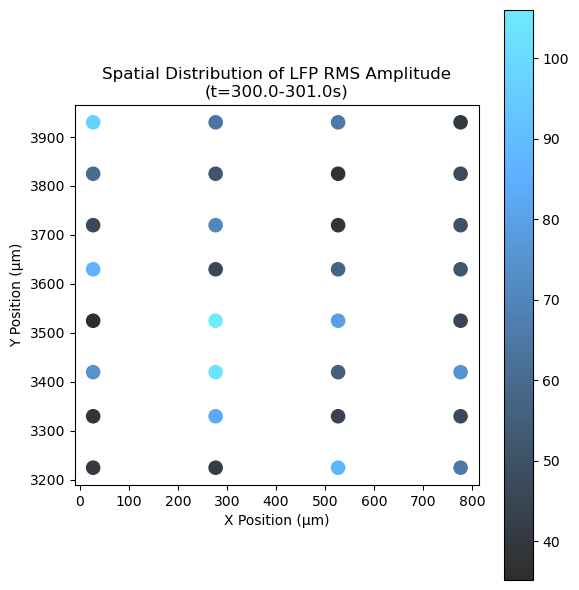

In [11]:
# Calculate RMS amplitude in a time window for each channel
t_start, t_end = 300.0, 301.0
sample = lfp.sel({DIM_TIME: slice(t_start, t_end)})

# Calculate RMS (root mean square) amplitude for each channel (1-D result per channel)
rms_amplitude = (sample ** 2).mean(dim=DIM_TIME) ** 0.5

# Use channel_values for a perceptually-uniform spatial heatmap
fig, ax = plt.subplots(figsize=(6, 6))
channel_values(rms_amplitude, ax=ax)
ax.set_title(f'Spatial Distribution of LFP RMS Amplitude\n(t={t_start}-{t_end}s)')
ax.set_aspect('equal')
plt.tight_layout()
